<a href="https://colab.research.google.com/github/Ravna95/Capstone-Project/blob/main/DataCo_Smart_Supply_Chain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
#Step 1: Import Libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import f_oneway

sns.set_style("whitegrid")

print("Libraries imported successfully.")



Libraries imported successfully.


In [29]:
#Step 2: Load All 9 Datasets from GitHub

import pandas as pd

url = 'https://raw.githubusercontent.com/Ravna95/Capstone-Project/main/'
base_url = 'https://raw.githubusercontent.com/Ravna95/Capstone-Project/main/'

customers = pd.read_csv(base_url + "Customers.csv")
orders = pd.read_csv(base_url + "Orders.csv")
order_items = pd.read_csv(base_url + "Order%20Items.csv")
products = pd.read_csv(base_url + "Products.csv")
categories = pd.read_csv(base_url + "Categories.csv")
departments = pd.read_csv(base_url + "Departments.csv")
shipping = pd.read_csv(base_url + "Shipping.csv")
geography = pd.read_csv(base_url + "Geography.csv")
payment_types = pd.read_csv(base_url + "Payment%20Types.csv")

print("All datasets loaded successfully.")



All datasets loaded successfully.


In [30]:
#Step 3: Explore Dataset Sizes

datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Products": products,
    "Categories": categories,
    "Departments": departments,
    "Shipping": shipping,
    "Geography": geography,
    "Payment Types": payment_types
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")


Customers: (20652, 11)
Orders: (65752, 11)
Order Items: (180519, 15)
Products: (118, 7)
Categories: (51, 3)
Departments: (11, 2)
Shipping: (65752, 3)
Geography: (64990, 9)
Payment Types: (4, 2)


In [31]:
#Step 4: Check Column Names

for name, df in datasets.items():
    print("n" + "="*60)
    print(name)
    print("="*60)

    print(df.columns.tolist())

n============================================================
Customers
['Customer Id', 'Customer Fname', 'Customer Lname', 'Customer Email', 'Customer Password', 'Customer Segment', 'Customer Street', 'Customer City', 'Customer State', 'Customer Country', 'Customer Zipcode']
n============================================================
Orders
['Order Id', 'Order Customer Id', 'Payment_Type_ID', 'Shipment_Id', 'Location_Id', 'order date (DateOrders)', 'Order Status', 'Delivery Status', 'Late_delivery_risk', 'Days for shipping (real)', 'Days for shipment (scheduled)']
n============================================================
Order Items
['Order Item Id', 'Order Id', 'Order Item Cardprod Id', 'Product Card Id', 'Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Order Item Total', 'Sales', 'Sales per customer', 'Benefit per order', 'Order Profit Per Order']
n==================================

In [32]:
#Step 5: Check Missing Values

for name, df in datasets.items():
    print("n" + "="*60)
    print(name)
    print("="*60)

    print(df.isnull().sum())

n============================================================
Customers
Customer Id          0
Customer Fname       0
Customer Lname       8
Customer Email       0
Customer Password    0
Customer Segment     0
Customer Street      0
Customer City        0
Customer State       0
Customer Country     0
Customer Zipcode     3
dtype: int64
n============================================================
Orders
Order Id                         0
Order Customer Id                0
Payment_Type_ID                  0
Shipment_Id                      0
Location_Id                      0
order date (DateOrders)          0
Order Status                     0
Delivery Status                  0
Late_delivery_risk               0
Days for shipping (real)         0
Days for shipment (scheduled)    0
dtype: int64
n============================================================
Order Items
Order Item Id               0
Order Id                    0
Order Item Cardprod Id      0
Product Card Id             0
C

In [33]:
#Step 6: Check Duplicate Records
for name, df in datasets.items():
    print(
        f"{name}: {df.duplicated().sum()} duplicate rows"
    )


Customers: 0 duplicate rows
Orders: 0 duplicate rows
Order Items: 0 duplicate rows
Products: 0 duplicate rows
Categories: 0 duplicate rows
Departments: 0 duplicate rows
Shipping: 0 duplicate rows
Geography: 0 duplicate rows
Payment Types: 0 duplicate rows


In [34]:
import numpy as np
import pandas as pd

print('Starting Step 7: Data Cleaning & Step 8: Feature Engineering...')

# ==========================================
# STEP 7: DATA CLEANING & PREPROCESSING
# ==========================================

# 7.1 Handle Missing Values in Products (Product Description is known to have nulls)
if 'Product Description' in products.columns:
  products['Product Description'] = products['Product Description'].fillna(
      'No Description Available'
  )

# 7.2 Convert Date Columns to Datetime Objects
# Orders dataset date
if 'order date (DateOrders)' in orders.columns:
  orders['order_date'] = pd.to_datetime(
      orders['order date (DateOrders)'], errors='coerce'
  )

# Shipping dataset date (if applicable)
if 'shipping date (DateOrders)' in shipping.columns:
  shipping['shipping_date'] = pd.to_datetime(
      shipping['shipping date (DateOrders)'], errors='coerce'
  )

print('Data cleaning completed: Dates parsed and missing descriptions handled.')

Starting Step 7: Data Cleaning & Step 8: Feature Engineering...
Data cleaning completed: Dates parsed and missing descriptions handled.


In [35]:
# ==========================================
# STEP 8: FEATURE ENGINEERING
# ==========================================

# 8.1 Merge core tables to create a unified master dataframe for analysis
df = order_items.merge(
    orders[
        [
            'Order Id',
            'Order Customer Id',
            'order_date',
            'Order Status',
            'Delivery Status',
            'Late_delivery_risk',
            'Days for shipping (real)',
            'Days for shipment (scheduled)',
        ]
    ],
    on='Order Id',
    how='left',
)

df = df.merge(
    products[['Product Card Id', 'Product Category Id', 'Product Name']],
    on='Product Card Id',
    how='left',
)

df = df.merge(
    categories[['Category Id', 'Category Name', 'Department Id']],
    left_on='Product Category Id',
    right_on='Category Id',
    how='left',
)

df = df.merge(departments, on='Department Id', how='left')

df = df.merge(
    customers[
        [
            'Customer Id',
            'Customer Segment',
            'Customer City',
            'Customer State',
            'Customer Country',
        ]
    ],
    on='Customer Id',
    how='left',
)

# 8.2 Extract Temporal Features
df['Year'] = df['order_date'].dt.year
df['Month'] = df['order_date'].dt.month
df['DayOfWeek'] = df['order_date'].dt.day_name()
df['YearMonth'] = df['order_date'].dt.to_period('M').astype(str)
df['Quarter'] = df['order_date'].dt.quarter

# 8.3 Feature Engineering: Supply Chain & Delivery Variance
# Difference between real shipping days and scheduled shipping days
df['Shipping_Delay_Variance'] = (
    df['Days for shipping (real)'] - df['Days for shipment (scheduled)']
)

# Binary flag for profit/loss per line item
df['Is_Profitable'] = df['Order Profit Per Order'].apply(
    lambda x: 1 if x > 0 else 0
)

print(
    'Feature engineering completed: Temporal, delivery variance, and profitability flags added.'
)
print(f'Master Analysis DataFrame Shape: {df.shape}')
print(df[['order_date', 'Year', 'Month', 'YearMonth', 'Shipping_Delay_Variance']].head(3))

Feature engineering completed: Temporal, delivery variance, and profitability flags added.
Master Analysis DataFrame Shape: (180519, 39)
           order_date  Year  Month YearMonth  Shipping_Delay_Variance
0 2018-01-31 22:56:00  2018      1   2018-01                       -1
1 2018-01-13 12:27:00  2018      1   2018-01                        1
2 2018-01-13 12:06:00  2018      1   2018-01                        0



OBJECTIVE 1: SALES PERFORMANCE METRICS
Total Gross Sales: $36,784,735.01
Total Net Revenue (Item Total): $33,054,402.38
Total Order Volume (Unique Orders): 65,752
Total Items Sold: 384,079

--- Yearly Sales Trends ---
   Year   Total_Sales  Total_Revenue  Order_Volume  Items_Sold
0  2015  1.234083e+07   1.108954e+07         20904      138480
1  2016  1.230382e+07   1.105600e+07         20859      137352
2  2017  1.180844e+07   1.061091e+07         21866      106124
3  2018  3.316501e+05   2.979521e+05          2123        2123

--- Top 5 Categories by Sales Revenue ---
       Category Name   Total_Sales  Order_Volume  Items_Sold
18           Fishing  6.929654e+06         15164       17325
12            Cleats  4.431943e+06         20386       73734
9   Camping & Hiking  4.118426e+06         12299       13729
10  Cardio Equipment  3.694843e+06         11355       37587
47   Women's Apparel  3.147800e+06         17869       62956

--- Top 5 Products by Sales Revenue ---
                

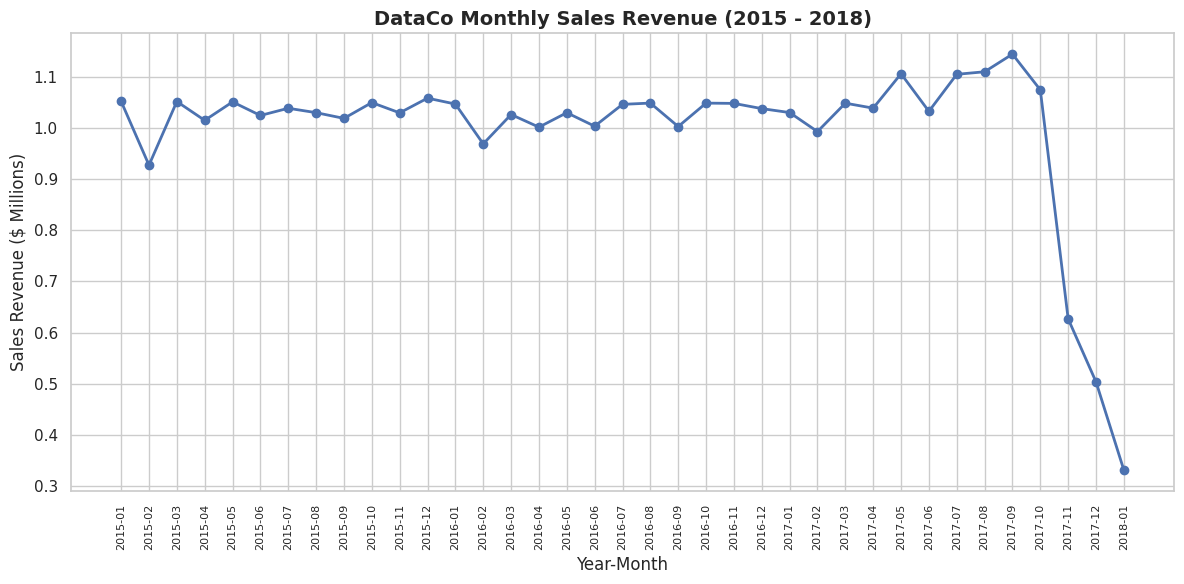

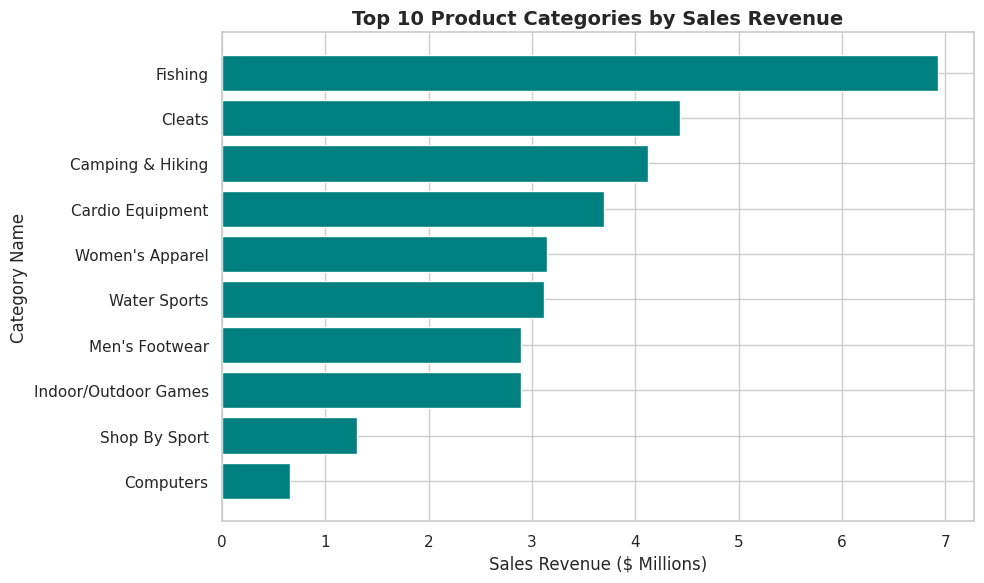


Analysis and visualizations rendered successfully!


In [36]:
# ==========================================
# OBJECTIVE 1: ANALYSE OVERALL SALES PERFORMANCE
# ==========================================

# 1. Merge datasets to establish complete transactional context
df = order_items.merge(
    orders[['Order Id', 'order date (DateOrders)', 'Order Status']],
    on='Order Id',
    how='left',
)
df = df.merge(
    products[['Product Card Id', 'Product Category Id', 'Product Name']],
    on='Product Card Id',
    how='left',
)
df = df.merge(
    categories[['Category Id', 'Category Name', 'Department Id']],
    left_on='Product Category Id',
    right_on='Category Id',
    how='left',
)
df = df.merge(departments, on='Department Id', how='left')

# Convert order date and extract temporal features
df['order_date'] = pd.to_datetime(df['order date (DateOrders)'])
df['Year'] = df['order_date'].dt.year
df['Month'] = df['order_date'].dt.month
df['YearMonth'] = df['order_date'].dt.to_period('M')

# 2. Calculate Total Sales Revenue and Order Volume
total_sales = df['Sales'].sum()
total_revenue = df['Order Item Total'].sum()
total_order_volume = df['Order Id'].nunique()
total_items_sold = df['Order Item Quantity'].sum()

print('\n' + '=' * 50)
print('OBJECTIVE 1: SALES PERFORMANCE METRICS')
print('=' * 50)
print(f'Total Gross Sales: ${total_sales:,.2f}')
print(f'Total Net Revenue (Item Total): ${total_revenue:,.2f}')
print(f'Total Order Volume (Unique Orders): {total_order_volume:,}')
print(f'Total Items Sold: {total_items_sold:,}')

# 3. Examine Yearly and Monthly Sales Trends
yearly_sales = (
    df.groupby('Year')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Revenue=('Order Item Total', 'sum'),
        Order_Volume=('Order Id', 'nunique'),
        Items_Sold=('Order Item Quantity', 'sum'),
    )
    .reset_index()
)

print('\n--- Yearly Sales Trends ---')
print(yearly_sales)

monthly_sales = (
    df.groupby('YearMonth')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Total_Revenue=('Order Item Total', 'sum'),
        Order_Volume=('Order Id', 'nunique'),
    )
    .reset_index()
)
monthly_sales['YearMonth_str'] = monthly_sales['YearMonth'].astype(str)

# 4. Identify Top Products and Categories Contributing to Sales
top_categories = (
    df.groupby('Category Name')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Order_Volume=('Order Id', 'nunique'),
        Items_Sold=('Order Item Quantity', 'sum'),
    )
    .reset_index()
    .sort_values(by='Total_Sales', ascending=False)
)

print('\n--- Top 5 Categories by Sales Revenue ---')
print(top_categories.head(5))

top_products = (
    df.groupby('Product Name')
    .agg(
        Total_Sales=('Sales', 'sum'),
        Order_Volume=('Order Id', 'nunique'),
        Items_Sold=('Order Item Quantity', 'sum'),
    )
    .reset_index()
    .sort_values(by='Total_Sales', ascending=False)
)

print('\n--- Top 5 Products by Sales Revenue ---')
print(top_products.head(5))

# ==========================================
# 5. GENERATE AND DISPLAY VISUALIZATIONS
# ==========================================

# Chart 1: Monthly Sales Trend Line Chart
plt.figure(figsize=(12, 6))
plt.plot(
    monthly_sales['YearMonth_str'],
    monthly_sales['Total_Sales'] / 1e6,
    marker='o',
    color='b',
    linewidth=2,
)
plt.title(
    'DataCo Monthly Sales Revenue (2015 - 2018)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Year-Month', fontsize=12)
plt.ylabel('Sales Revenue ($ Millions)', fontsize=12)
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.savefig('monthly_sales_trend.png', dpi=300)
plt.show()  # Renders the visualization inline in your notebook/Colab

# Chart 2: Top 10 Product Categories Bar Chart
plt.figure(figsize=(10, 6))
top_cat_plot = top_categories.head(10).sort_values(
    by='Total_Sales', ascending=True
)
plt.barh(
    top_cat_plot['Category Name'],
    top_cat_plot['Total_Sales'] / 1e6,
    color='teal',
)
plt.title(
    'Top 10 Product Categories by Sales Revenue', fontsize=14, fontweight='bold'
)
plt.xlabel('Sales Revenue ($ Millions)', fontsize=12)
plt.ylabel('Category Name', fontsize=12)
plt.tight_layout()
plt.savefig('top_categories.png', dpi=300)
plt.show()  # Renders the visualization inline in your notebook/Colab

print('\nAnalysis and visualizations rendered successfully!')

Loading datasets...
Datasets merged successfully for delivery analysis.

OBJECTIVE 2: DELIVERY PERFORMANCE METRICS
Total Orders Analyzed: 65,752
Late Deliveries: 36,048
Percentage of Late Deliveries: 54.82%

--- Shipping Duration Comparison ---
Average Real Shipping Days: 3.50 days
Average Scheduled Shipping Days: 2.93 days
Average Delay Variance (Real - Scheduled): 0.57 days

--- Performance Across Shipping Modes ---
 Shipping Mode  Total_Orders  Late_Orders  Avg_Real_Days  Avg_Scheduled_Days  Late_Delivery_Percentage_By_Mode
   First Class         10079         9602       2.000000                 1.0                         95.267388
  Second Class         12778         9803       4.001565                 2.0                         76.717796
      Same Day          3571         1648       0.483618                 0.0                         46.149538
Standard Class         39324        14995       3.996898                 4.0                         38.131930


/tmp/ipykernel_1768/3476527273.py:98: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


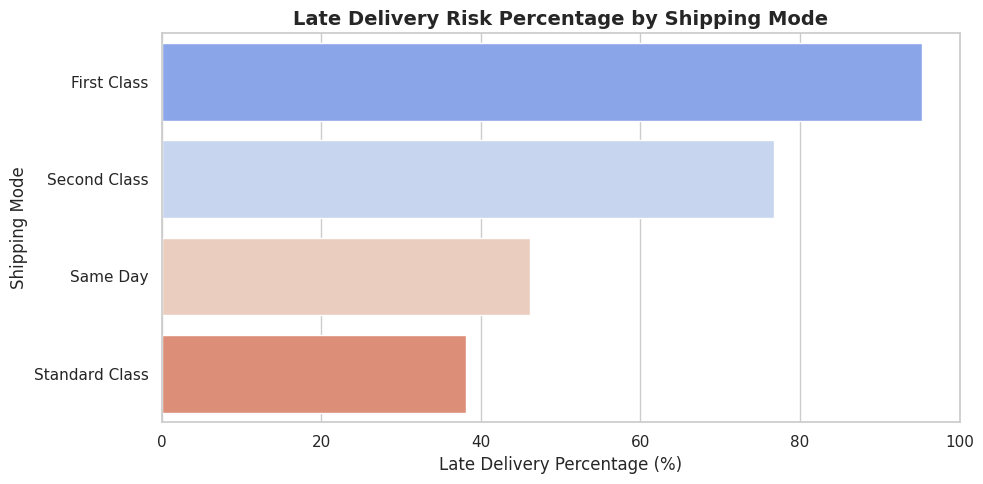


Objective 2 analysis and visualization complete!


In [37]:

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style='whitegrid')

# 1. Load datasets from your GitHub repository (or local directory)
base_url = 'https://raw.githubusercontent.com/Ravna95/Capstone-Project/main/'

print('Loading datasets...')
orders = pd.read_csv(base_url + 'Orders.csv', encoding='latin1')
shipping = pd.read_csv(base_url + 'Shipping.csv', encoding='latin1')

# If working locally, you can use:
# orders = pd.read_csv('Orders.csv', encoding='latin1')
# shipping = pd.read_csv('Shipping.csv', encoding='latin1')

# 2. Merge Orders and Shipping datasets
# Note: 'Shipment_Id' or order identification keys connect these datasets
df_delivery = orders.merge(shipping, on='Shipment_Id', how='left')

# Ensure date columns are parsed correctly if needed
if 'order date (DateOrders)' in df_delivery.columns:
  df_delivery['order_date'] = pd.to_datetime(
      df_delivery['order date (DateOrders)'], errors='coerce'
  )

print('Datasets merged successfully for delivery analysis.')

# ==========================================
# 3. CALCULATE PERCENTAGE OF LATE DELIVERIES
# ==========================================
# Using the 'Late_delivery_risk' column (1 = Late risk/Late delivery, 0 = On time/Ahead)
total_orders = len(df_delivery)
late_orders = df_delivery['Late_delivery_risk'].sum()
late_delivery_percentage = (late_orders / total_orders) * 100

print('\n' + '=' * 50)
print('OBJECTIVE 2: DELIVERY PERFORMANCE METRICS')
print('=' * 50)
print(f'Total Orders Analyzed: {total_orders:,}')
print(f'Late Deliveries: {late_orders:,}')
print(f'Percentage of Late Deliveries: {late_delivery_percentage:.2f}%')

# ==========================================
# 4. COMPARE ACTUAL VS. SCHEDULED SHIPPING DAYS
# ==========================================
avg_real_days = df_delivery['Days for shipping (real)'].mean()
avg_scheduled_days = df_delivery['Days for shipment (scheduled)'].mean()

print('\n--- Shipping Duration Comparison ---')
print(f'Average Real Shipping Days: {avg_real_days:.2f} days')
print(f'Average Scheduled Shipping Days: {avg_scheduled_days:.2f} days')

# Calculate shipping variance (Real minus Scheduled)
df_delivery['Shipping_Delay_Variance'] = (
    df_delivery['Days for shipping (real)']
    - df_delivery['Days for shipment (scheduled)']
)
avg_variance = df_delivery['Shipping_Delay_Variance'].mean()
print(f'Average Delay Variance (Real - Scheduled): {avg_variance:.2f} days')

# ==========================================
# 5. COMPARE PERFORMANCE ACROSS SHIPPING MODES
# ==========================================
# Group by Shipping Mode (assuming 'Shipping Mode' is in the shipping or orders table)
shipping_mode_col = (
    'Shipping Mode' if 'Shipping Mode' in df_delivery.columns else 'shipping mode'
)

if shipping_mode_col in df_delivery.columns:
  shipping_perf = (
      df_delivery.groupby(shipping_mode_col)
      .agg(
          Total_Orders=('Order Id', 'count'),
          Late_Orders=('Late_delivery_risk', 'sum'),
          Avg_Real_Days=('Days for shipping (real)', 'mean'),
          Avg_Scheduled_Days=('Days for shipment (scheduled)', 'mean'),
      )
      .reset_index()
  )

  shipping_perf['Late_Delivery_Percentage_By_Mode'] = (
      shipping_perf['Late_Orders'] / shipping_perf['Total_Orders']
  ) * 100
  shipping_perf = shipping_perf.sort_values(
      by='Late_Delivery_Percentage_By_Mode', ascending=False
  )

  print('\n--- Performance Across Shipping Modes ---')
  print(shipping_perf.to_string(index=False))

  # ==========================================
  # 6. GENERATE VISUALIZATIONS
  # ==========================================
  plt.figure(figsize=(10, 5))
  sns.barplot(
      x='Late_Delivery_Percentage_By_Mode',
      y=shipping_mode_col,
      data=shipping_perf,
      palette='coolwarm',
  )
  plt.title(
      'Late Delivery Risk Percentage by Shipping Mode',
      fontsize=14,
      fontweight='bold',
  )
  plt.xlabel('Late Delivery Percentage (%)', fontsize=12)
  plt.ylabel('Shipping Mode', fontsize=12)
  plt.tight_layout()
  plt.savefig('late_delivery_by_shipping_mode.png', dpi=300)
  plt.show()
else:
  print('Shipping Mode column not found in the merged dataset.')

print('\nObjective 2 analysis and visualization complete!')

Loading datasets directly from GitHub...
Merging datasets for Objective 3...
Dataset shape after merges: (180519, 25)

--- 1. Product & Category Profitability ---
Top 10 Most Profitable Products:
                                      Product Name   Total_Sales  \
24       Field & Stream Sportsman 16 Gun Fire Safe  6.929654e+06   
71                Perfect Fitness Perfect Rip Deck  4.421143e+06   
21   Diamondback Women's Serene Classic Comfort Bi  4.118426e+06   
61               Nike Men's Free 5.0+ Running Shoe  3.667633e+06   
59            Nike Men's Dri-FIT Victory Golf Polo  3.147800e+06   
70                     Pelican Sunstream 100 Kayak  3.099845e+06   
67                O'Brien Men's Neoprene Life Vest  2.888994e+06   
56         Nike Men's CJ Elite 2 TD Football Cleat  2.891758e+06   
102  Under Armour Girls' Toddler Spine Surge Runni  1.269083e+06   
18                                     Dell Laptop  6.630000e+05   

      Total_Profit  Avg_Profit_Margin  
24   756220.767

/tmp/ipykernel_1768/1318775448.py:105: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1768/1318775448.py:117: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(



Analysis complete! Visualizations saved to 'objective_3_analysis.png'.


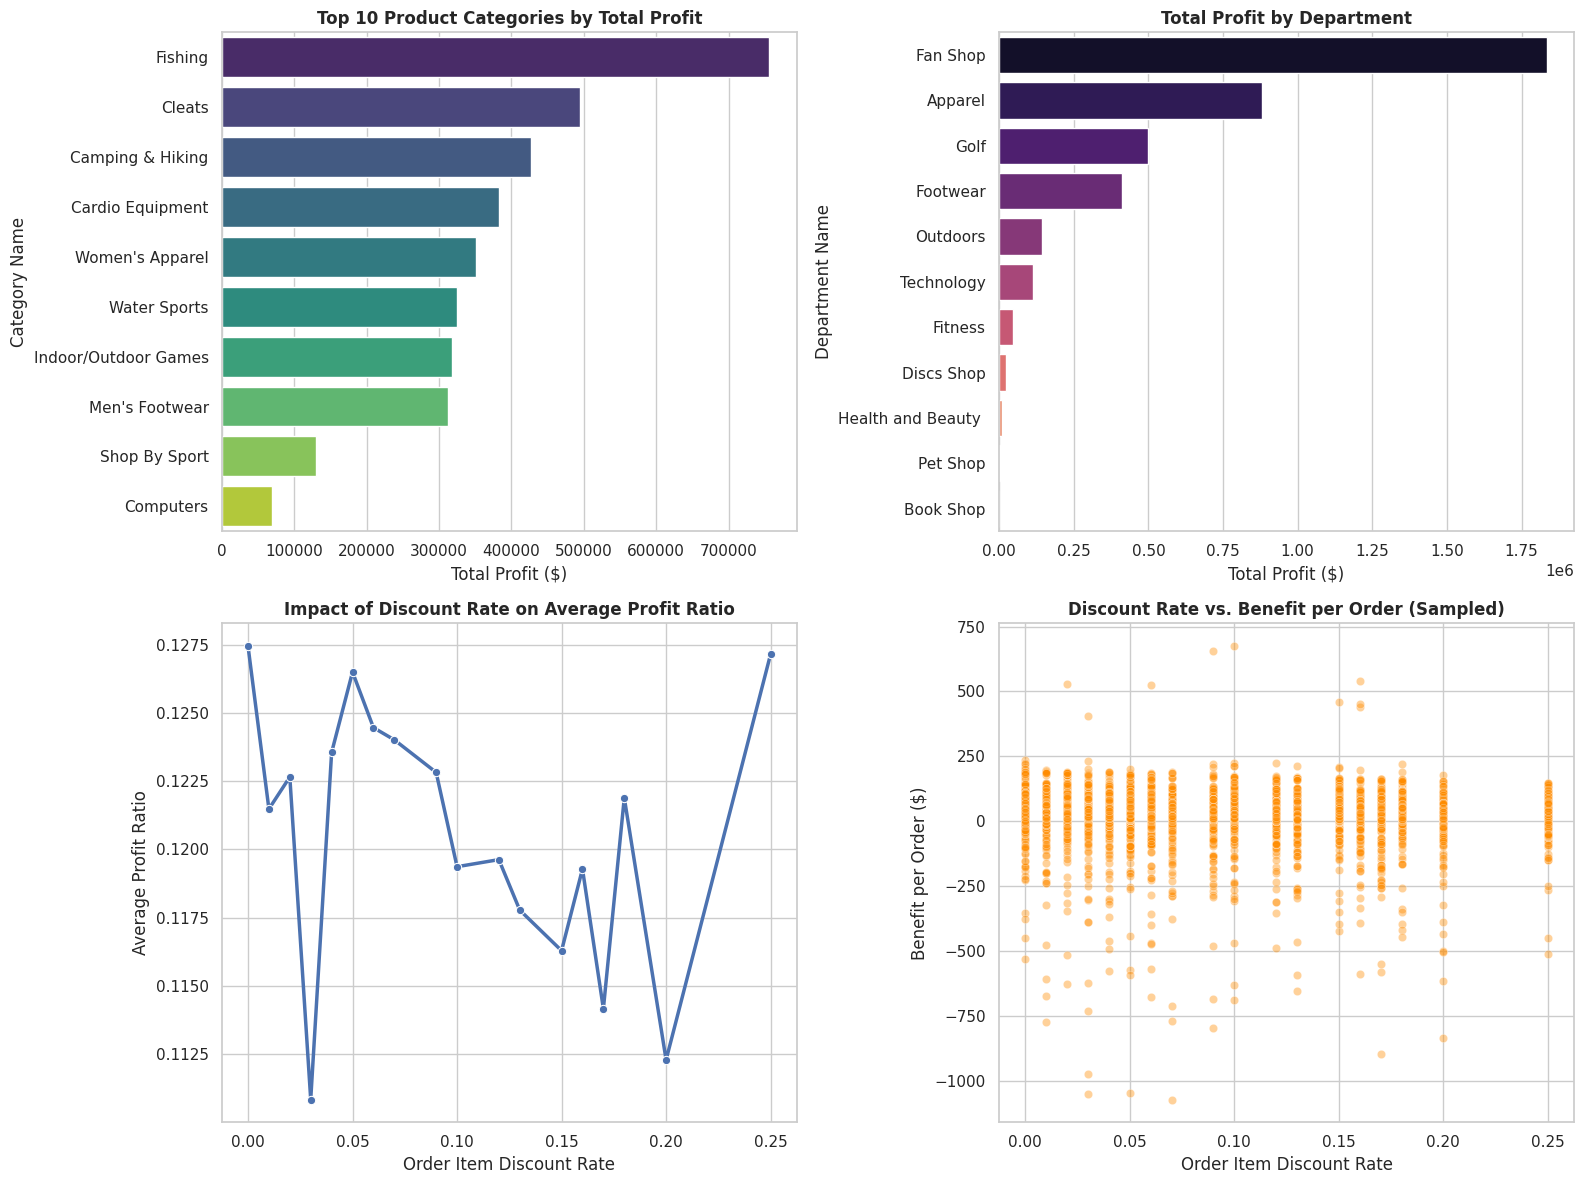

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.autolayout': True})

# GitHub raw base URL for your repository
# (If your default branch is 'master' instead of 'main', change 'main' below accordingly)
github_base_url = "https://raw.githubusercontent.com/Ravna95/Capstone-Project/main/"

print("Loading datasets directly from GitHub...")
order_items = pd.read_csv(github_base_url + "Order%20Items.csv", encoding='latin1')
products = pd.read_csv(github_base_url + "Products.csv", encoding='latin1')
categories = pd.read_csv(github_base_url + "Categories.csv", encoding='latin1')
departments = pd.read_csv(github_base_url + "Departments.csv", encoding='latin1')

print("Merging datasets for Objective 3...")
# Merge Order Items with Products
df = order_items.merge(products, on='Product Card Id', how='left')

# Merge with Categories
df = df.merge(categories, left_on='Product Category Id', right_on='Category Id', how='left', suffixes=('', '_cat'))

# Merge with Departments
df = df.merge(departments, on='Department Id', how='left', suffixes=('', '_dept'))

print("Dataset shape after merges:", df.shape)

# ==========================================
# 1. Most and Least Profitable Products and Categories
# ==========================================
print("\n--- 1. Product & Category Profitability ---")

# Aggregate by Product Name
product_perf = df.groupby('Product Name').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Benefit per order', 'sum'),
    Total_Quantity=('Order Item Quantity', 'sum'),
    Avg_Profit_Margin=('Order Item Profit Ratio', 'mean')
).reset_index()

top_products = product_perf.sort_values(by='Total_Profit', ascending=False).head(10)
bottom_products = product_perf.sort_values(by='Total_Profit', ascending=True).head(10)

print("Top 10 Most Profitable Products:")
print(top_products[['Product Name', 'Total_Sales', 'Total_Profit', 'Avg_Profit_Margin']])

# Aggregate by Category Name
category_perf = df.groupby('Category Name').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Benefit per order', 'sum'),
    Total_Quantity=('Order Item Quantity', 'sum'),
    Avg_Profit_Margin=('Order Item Profit Ratio', 'mean')
).reset_index()

top_categories = category_perf.sort_values(by='Total_Profit', ascending=False).head(10)
bottom_categories = category_perf.sort_values(by='Total_Profit', ascending=True).head(10)

print("\nTop 10 Most Profitable Categories:")
print(top_categories[['Category Name', 'Total_Sales', 'Total_Profit', 'Avg_Profit_Margin']])

print("\nBottom 10 Least Profitable Categories:")
print(bottom_categories[['Category Name', 'Total_Sales', 'Total_Profit', 'Avg_Profit_Margin']])

# ==========================================
# 2. Compare Revenue and Profit Across Departments
# ==========================================
print("\n--- 2. Department Revenue and Profit ---")
dept_perf = df.groupby('Department Name').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Benefit per order', 'sum'),
    Total_Quantity=('Order Item Quantity', 'sum'),
    Avg_Profit_Margin=('Order Item Profit Ratio', 'mean')
).reset_index().sort_values(by='Total_Profit', ascending=False)

print(dept_perf[['Department Name', 'Total_Sales', 'Total_Profit', 'Avg_Profit_Margin']])

# ==========================================
# 3. Examine Associations Between Discounts and Profitability
# ==========================================
print("\n--- 3. Discounts vs. Profitability ---")
discount_corr = df[['Order Item Discount Rate', 'Order Item Discount', 'Benefit per order', 'Order Item Profit Ratio']].corr()
print("Correlation Matrix:")
print(discount_corr)

discount_group = df.groupby('Order Item Discount Rate').agg(
    Order_Count=('Order Item Id', 'count'),
    Avg_Sales=('Sales', 'mean'),
    Avg_Profit=('Benefit per order', 'mean'),
    Avg_Profit_Ratio=('Order Item Profit Ratio', 'mean')
).reset_index()

print("\nPerformance by Discount Rate:")
print(discount_group)

# ==========================================
# 4. Generate Visualizations for Objective 3
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Top 10 Categories by Profit
sns.barplot(
    data=top_categories.head(10),
    x='Total_Profit',
    y='Category Name',
    ax=axes[0, 0],
    palette='viridis'
)
axes[0, 0].set_title('Top 10 Product Categories by Total Profit', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Total Profit ($)')
axes[0, 0].set_ylabel('Category Name')

# Plot 2: Total Profit by Department
sns.barplot(
    data=dept_perf,
    x='Total_Profit',
    y='Department Name',
    ax=axes[0, 1],
    palette='magma'
)
axes[0, 1].set_title('Total Profit by Department', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Total Profit ($)')
axes[0, 1].set_ylabel('Department Name')

# Plot 3: Discount Rate vs Average Profit Ratio
sns.lineplot(
    data=discount_group,
    x='Order Item Discount Rate',
    y='Avg_Profit_Ratio',
    marker='o',
    ax=axes[1, 0],
    color='b',
    linewidth=2.5
)
axes[1, 0].set_title('Impact of Discount Rate on Average Profit Ratio', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Order Item Discount Rate')
axes[1, 0].set_ylabel('Average Profit Ratio')

# Plot 4: Scatter Plot of Discount Rate vs Benefit per Order
sample_df = df.sample(n=min(5000, len(df)), random_state=42)
sns.scatterplot(
    data=sample_df,
    x='Order Item Discount Rate',
    y='Benefit per order',
    alpha=0.4,
    ax=axes[1, 1],
    color='darkorange'
)
axes[1, 1].set_title('Discount Rate vs. Benefit per Order (Sampled)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Order Item Discount Rate')
axes[1, 1].set_ylabel('Benefit per Order ($)')

plt.tight_layout()
plt.savefig('objective_3_analysis.png', dpi=300)
print("\nAnalysis complete! Visualizations saved to 'objective_3_analysis.png'.")

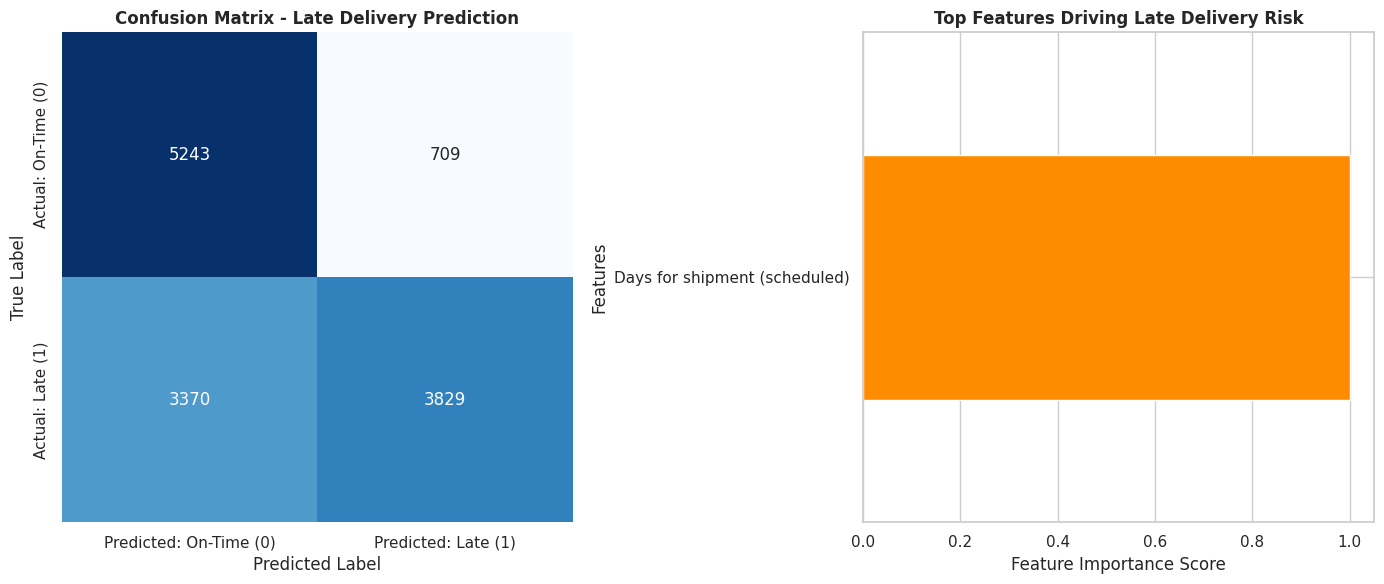

Objective 4 visualizations generated and saved successfully!


In [2]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Predicted: On-Time (0)', 'Predicted: Late (1)'],
            yticklabels=['Actual: On-Time (0)', 'Actual: Late (1)'])
axes[0].set_title('Confusion Matrix - Late Delivery Prediction', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# 2. Feature Importance Plot (if using RandomForest)
if hasattr(model, 'feature_importances_'):
    importances = model.feature_importances_
    feature_names = X.columns
    feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=True)

    feat_imp.tail(10).plot(kind='barh', ax=axes[1], color='darkorange')
    axes[1].set_title('Top Features Driving Late Delivery Risk', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Feature Importance Score')
    axes[1].set_ylabel('Features')

plt.tight_layout()
plt.savefig('objective_4_predictive_results.png', dpi=300)
plt.show()
print("Objective 4 visualizations generated and saved successfully!")

Loading datasets for Objective 5...
Preprocessing and aggregating customer data...
Dataset prepared with 20652 samples and 4 features.
Training Random Forest Classifier for Customer Segments...

Model Accuracy: 0.4495279593318809

Classification Report:
               precision    recall  f1-score   support

    Consumer       0.53      0.70      0.60      2153
   Corporate       0.31      0.23      0.27      1260
 Home Office       0.18      0.09      0.12       718

    accuracy                           0.45      4131
   macro avg       0.34      0.34      0.33      4131
weighted avg       0.40      0.45      0.41      4131



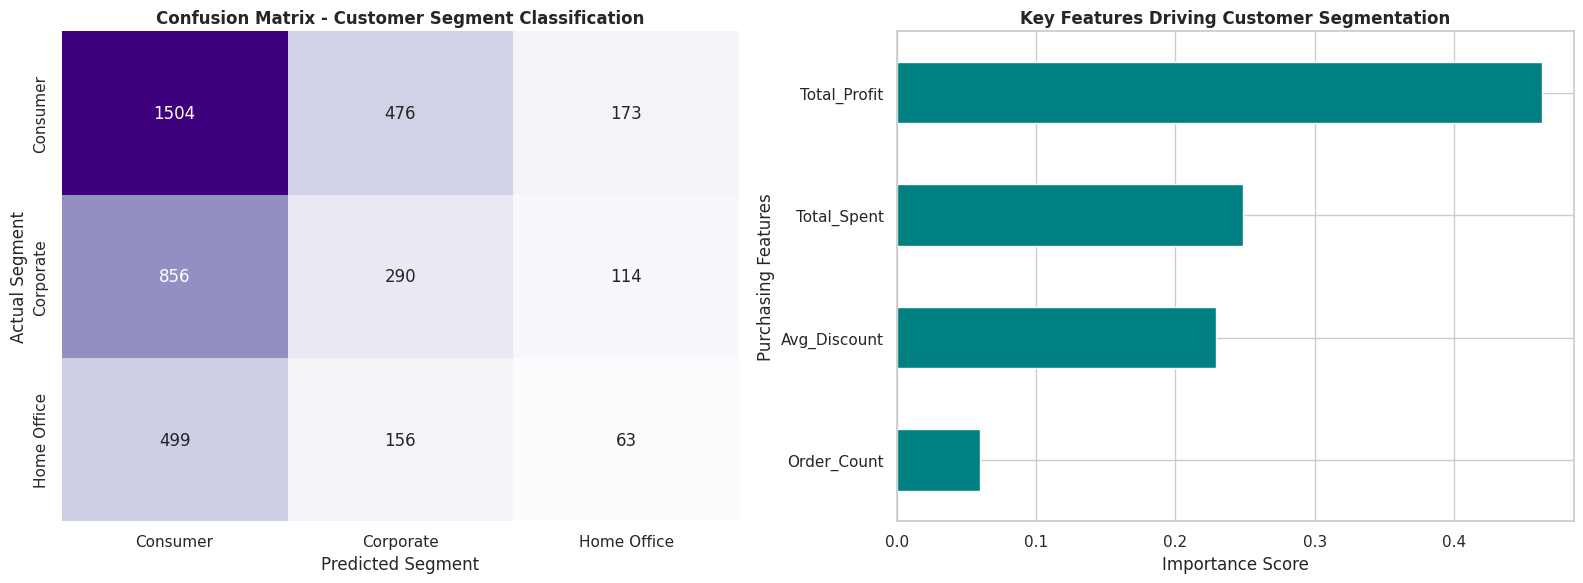


Objective 5 analysis complete! Visualizations saved to 'objective_5_predictive_results.png'.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.autolayout': True})

# GitHub raw base URL for your repository
github_base_url = "https://raw.githubusercontent.com/Ravna95/Capstone-Project/main/"

print("Loading datasets for Objective 5...")
customers = pd.read_csv(github_base_url + "Customers.csv", encoding='latin1')
orders = pd.read_csv(github_base_url + "Orders.csv", encoding='latin1')
order_items = pd.read_csv(github_base_url + "Order%20Items.csv", encoding='latin1')

print("Preprocessing and aggregating customer data...")
# Aggregate order items by customer / order to get monetary and quantity features
item_summary = order_items.groupby('Customer Id').agg(
    Total_Spent=('Sales', 'sum'),
    Total_Profit=('Benefit per order', 'sum'),
    Avg_Discount=('Order Item Discount Rate', 'mean'),
    Order_Count=('Order Id', 'nunique')
).reset_index()

# Merge customer master data with aggregated transaction metrics
# (Assuming Customers.csv uses 'Customer Id' or similar key)
cust_id_col = 'Customer Id' if 'Customer Id' in customers.columns else 'Customer Id'
df_cust = customers.merge(item_summary, on='Customer Id', how='inner')

# Define features (X) and target (y: Customer Segment)
# We will predict the 'Customer Segment' based on purchasing behavior
features = ['Total_Spent', 'Total_Profit', 'Avg_Discount', 'Order_Count']
X = df_cust[features].fillna(0)

# Encode target variable (Customer Segment) into numeric labels if it is categorical
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(df_cust['Customer Segment'])

print(f"Dataset prepared with {X.shape[0]} samples and {X.shape[1]} features.")

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Random Forest Classifier
print("Training Random Forest Classifier for Customer Segments...")
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predictions and Evaluation
y_pred = model.predict(X_test)
print("\nModel Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=le.classes_))

# ==========================================
# Generate Visualizations for Objective 5
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', cbar=False, ax=axes[0],
            xticklabels=le.classes_,
            yticklabels=le.classes_)
axes[0].set_title('Confusion Matrix - Customer Segment Classification', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Segment')
axes[0].set_ylabel('Actual Segment')

# Plot 2: Feature Importance Bar Chart
importances = model.feature_importances_
feat_imp = pd.Series(importances, index=features).sort_values(ascending=True)

feat_imp.plot(kind='barh', ax=axes[1], color='teal')
axes[1].set_title('Key Features Driving Customer Segmentation', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Importance Score')
axes[1].set_ylabel('Purchasing Features')

plt.tight_layout()
plt.savefig('objective_5_predictive_results.png', dpi=300)
plt.show()
print("\nObjective 5 analysis complete! Visualizations saved to 'objective_5_predictive_results.png'.")